# Fig. 4: BarFly quantifies spontaneous against induced mutagenesis

4c  the mutant-number CCDF of each population fitted to a spontaneous-only model.
      The unexposed control fits well; both UV-exposed populations do not, and the fit
      compensates by inflating the apparent spontaneous rate to ~1e-6.

  4d  the same data fitted to a model with both spontaneous and induced mutagenesis.
      All three now fit, with the control's induced rate indistinguishable from zero
      and the UV populations' spontaneous rates back in line with it -- the signature
      of a genuine second mode of adaptation rather than a raised mutation rate.

Both panels use the maximum-likelihood fit at k = 4000 bins.  That bin count is where
the two estimators agree: as k grows, the population per virtual lineage falls until
most lineages produce no mutants at all, and the likelihood -- dominated by those
empty lineages -- can no longer distinguish spontaneous from induced mutations, while
least squares stays informative because it weights the tail.

Requires `20260907_expt3_fits.py`.  Runtime: ~1 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from barfly import expt3, ld
from barfly.plotting import colorTable, use_paper_style

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
CACHE = ROOT / "cache"
use_paper_style()

K_PLOT = 4000
SEED = 20260907
np.random.seed(SEED)
t_start = time.time()

with open(CACHE / "expt3_precompute.pkl", "rb") as f:
    blocks = pickle.load(f)["blocks"]
mle_tbl = pd.read_csv(CACHE / "expt3_mle_summary.csv")

## The CCDF overlay

Data against best-fit theory, one panel per population. Used twice below: once for the spontaneous-only model and once for the combined one.

In [2]:
def plot_ccdf_overlay(library, fits, n_bins, path, model, n_replicates=10_000_000):
    """Mutant-number CCDF with the best-fit theory, one panel per population.

    `model` selects which fit to draw: "spontaneous" takes the mu_ind = 0 slice,
    "combined" the full (mu, mu_ind) optimum.  `fits` is either estimator's summary
    table, so the same call renders the maximum-likelihood and the least-squares
    version of the panel.

    Data are the observed mutant numbers per virtual lineage, scaled by the fitted
    alpha.  Theory is a fresh simulation at the best-fit rates: the spontaneous part
    from the Luria-Delbruck process, plus -- for the combined model -- an independent
    Poisson(mu_ind * N) draw per replicate, which is what induced mutations
    contribute.
    """
    theory_x = np.logspace(0, 4, 100)

    figure, axes = plt.subplots(1, len(expt3.KEYS), figsize=(0.8 * 16, 0.8 * 4),
                                sharey=True, sharex=True)
    for axis, key in zip(axes, expt3.KEYS):
        row = fits.loc[(fits.key == key) & (fits.k == n_bins)].iloc[0]
        block = library[(key, n_bins)]
        colour = colorTable["o"] if "UV" in key else colorTable["k"]

        mu = row["mu_best_muind0"] if model == "spontaneous" else row["mu_best"]
        simulated = ld.simulate_ld(float(mu), 1.0, n_replicates,
                                   block["population_per_bin"])
        if model == "combined" and row["mu_ind_best"] > 0:
            simulated = simulated + np.random.poisson(
                float(row["mu_ind_best"]) * block["population_per_bin"], n_replicates)
        simulated.sort()
        theory_y = ld.ccdf_of_sorted(simulated, theory_x)
        del simulated

        observed = np.sort(row["alpha"] * block["mutants_at_alpha1"])
        # log-spaced up to the fifteenth largest, then each jackpot individually
        plot_x = np.concatenate([np.logspace(0, np.log10(observed[-15]), 40),
                                 observed[-15:]])
        axis.plot(plot_x, ld.ccdf_of_sorted(observed, plot_x), ".",
                  markersize=25, color=colour, rasterized=True, alpha=0.3)
        axis.plot(theory_x, theory_y, "-", color=colour, linewidth=3.5)

        annotation = (f"$\\mu$ = {mu:.1e}" if model == "spontaneous" else
                      f"$\\mu$ = {mu:.1e}\n"
                      f"$\\mu_{{\\mathrm{{ind}}}}$ = {row['mu_ind_best']:.1e}")
        axis.text(0.95, 0.95, annotation, transform=axis.transAxes,
                  verticalalignment="top", horizontalalignment="right")
        axis.set_xscale("log")
        axis.set_yscale("log")

    axes[0].set_xlim(8e-1, 1e4)
    axes[0].set_ylim(1e-4, 2)
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()

--- maximum-likelihood fits at k = 4000 ---
  BY4741                 mu = 3.39e-07  mu_ind = 0.00e+00   (spontaneous-only model: mu = 3.39e-07)
  BY4741 + UV repl. 1    mu = 2.22e-07  mu_ind = 1.93e-06   (spontaneous-only model: mu = 9.10e-07)
  BY4741 + UV repl. 2    mu = 2.56e-07  mu_ind = 1.53e-06   (spontaneous-only model: mu = 9.10e-07)


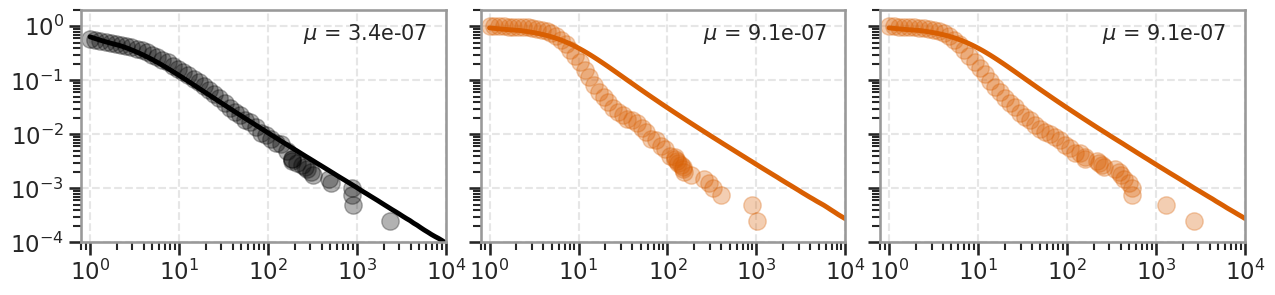

4c written (4s)


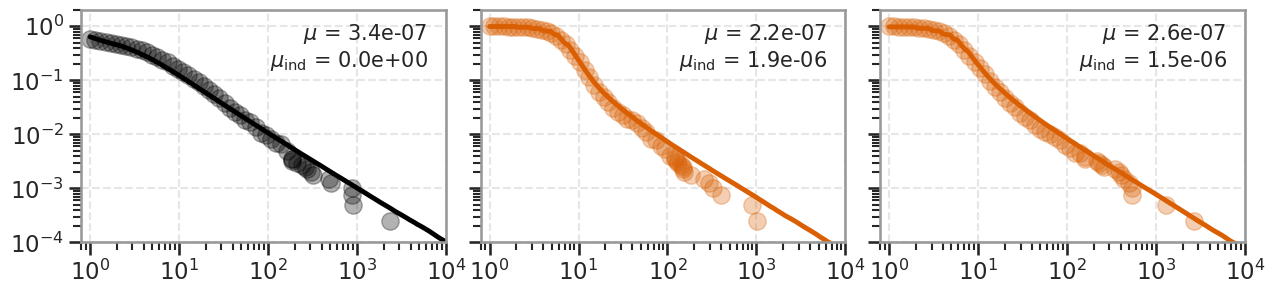

4d written (8s)
Done in 8s.


In [3]:
sys.path.insert(0, str(ROOT))
from barfly import expt3, ld
from barfly.plotting import colorTable                              # noqa: E402
from barfly.plotting import use_paper_style                 # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
CACHE = ROOT / "cache"
use_paper_style()

K_PLOT = 4000
SEED = 20260907
np.random.seed(SEED)
t_start = time.time()

with open(CACHE / "expt3_precompute.pkl", "rb") as f:
    blocks = pickle.load(f)["blocks"]
mle_tbl = pd.read_csv(CACHE / "expt3_mle_summary.csv")

print(f"--- maximum-likelihood fits at k = {K_PLOT} ---")
for key in expt3.KEYS:
    r = mle_tbl.loc[(mle_tbl.key == key) & (mle_tbl.k == K_PLOT)].iloc[0]
    print(f"  {expt3.KEY_LABELS[key]:22s} mu = {r.mu_best:.2e}  mu_ind = {r.mu_ind_best:.2e}"
          f"   (spontaneous-only model: mu = {r.mu_best_muind0:.2e})")

plot_ccdf_overlay(blocks, mle_tbl, K_PLOT,
                     OUT / "fig04c_bestfitCCDF_muind0_MLE.svg", model="spontaneous")
print(f"4c written ({time.time()-t_start:.0f}s)")
plot_ccdf_overlay(blocks, mle_tbl, K_PLOT,
                     OUT / "fig04d_bestfitCCDF_MLE.svg", model="combined")
print(f"4d written ({time.time()-t_start:.0f}s)")
print(f"Done in {time.time()-t_start:.0f}s.")